# Control óptimo de EDOs — Clase 2
**Principio del Máximo: problema básico**

FCEN–UBA. Bibliografía principal: Lenhart & Workman, *Optimal Control Applied to Biological Models* (2007).

> Convención del curso: problemas de **máximo** y Hamiltoniano $H = L + \lambda f$.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, solve_bvp
from scipy.optimize import brentq, minimize
plt.rcParams.update({'figure.figsize': (7, 3.5), 'axes.grid': True, 'grid.alpha': 0.3})

## 1. El problema de dos puntos con `solve_bvp`
Ejemplo 2 de la clase: $\min\frac12\int_0^1(3x^2+u^2)$, $\dot x=x+u$, $x(0)=1$.
El PMP da $u=\lambda$ y el sistema $\dot x=x+\lambda$, $\dot\lambda=3x-\lambda$, $x(0)=1$, $\lambda(1)=0$.

The algorithm converged to the desired accuracy.


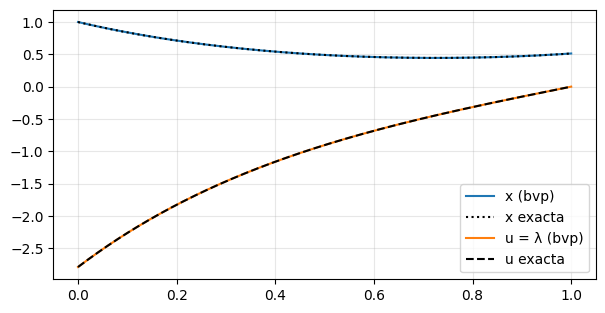

error máx en u: 2.254521769273765e-08


In [2]:
def sistema(t, y):
    x, lam = y
    return np.vstack([x + lam, 3*x - lam])

def bordes(ya, yb):
    return np.array([ya[0] - 1.0, yb[1]])   # x(0)=1, lambda(1)=0

t = np.linspace(0, 1, 50)
sol = solve_bvp(sistema, bordes, t, np.zeros((2, t.size)))
print(sol.message)

c = 3*np.exp(-4)/(3*np.exp(-4) + 1); d = 1/(3*np.exp(-4) + 1)
tt = np.linspace(0, 1, 300)
x_ex = c*np.exp(2*tt) + d*np.exp(-2*tt); u_ex = c*np.exp(2*tt) - 3*d*np.exp(-2*tt)
x_num, u_num = sol.sol(tt)
plt.plot(tt, x_num, label='x (bvp)'); plt.plot(tt, x_ex, 'k:', label='x exacta')
plt.plot(tt, u_num, label='u = λ (bvp)'); plt.plot(tt, u_ex, 'k--', label='u exacta')
plt.legend(); plt.show()
print('error máx en u:', np.abs(u_num - u_ex).max())

## 2. Ejercicio 1: $\min\int_0^1 (x^2+u^2)$, $\dot x = u$, $x(0)=1$
Completar `sistema1` y `bordes1` y comparar con $x^*(t)=\cosh(1-t)/\cosh 1$.

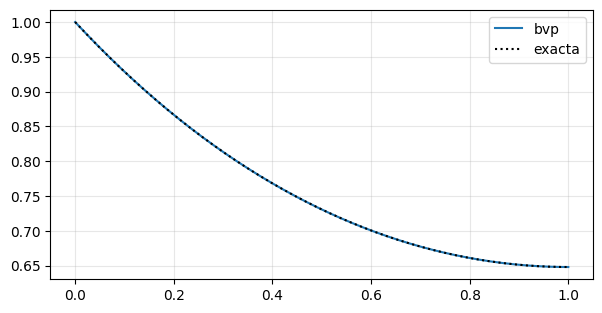

u*(0) = -0.7615941558545799  teoría: -tanh(1) = -0.7615941559557649


In [3]:
# H = -x^2 - u^2 + lam*u  ->  u = lam/2,  lam' = 2x
def sistema1(t, y):
    x, lam = y
    return np.vstack([lam/2, 2*x])

def bordes1(ya, yb):
    return np.array([ya[0] - 1.0, yb[1]])

sol1 = solve_bvp(sistema1, bordes1, t, np.zeros((2, t.size)))
plt.plot(tt, sol1.sol(tt)[0], label='bvp'); plt.plot(tt, np.cosh(1 - tt)/np.cosh(1), 'k:', label='exacta')
plt.legend(); plt.show()
print('u*(0) =', sol1.sol(0)[1]/2, ' teoría: -tanh(1) =', -np.tanh(1))

## 3. ¿Algún control le gana al del PMP?
Simulamos muchos controles perturbados y calculamos el costo (a minimizar).

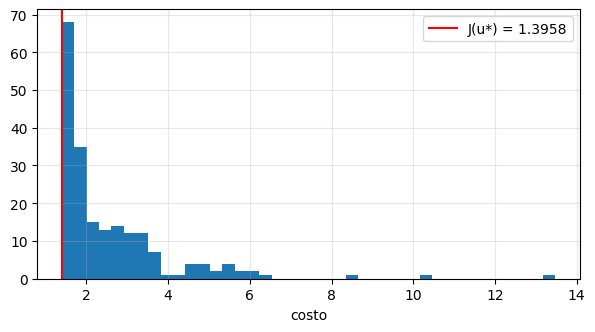

mínimo de los perturbados: 1.402583820253548


In [4]:
tg = np.linspace(0, 1, 2001)
u_opt = c*np.exp(2*tg) - 3*d*np.exp(-2*tg)

def costo(u):
    s = solve_ivp(lambda s, x: x + np.interp(s, tg, u), [0, 1], [1.0], t_eval=tg, rtol=1e-9)
    v = 3*s.y[0]**2 + u**2
    return 0.5*float(np.sum(0.5*(v[1:] + v[:-1])*np.diff(tg)))

rng = np.random.default_rng(0)
vals = [costo(u_opt + 0.6*(a[0] + a[1]*tg + a[2]*np.sin(np.pi*tg) + a[3]*np.cos(3*tg)))
        for a in rng.normal(size=(200, 4))]
plt.hist(vals, bins=40); plt.axvline(costo(u_opt), color='r', label=f'J(u*) = {costo(u_opt):.4f}')
plt.legend(); plt.xlabel('costo'); plt.show()
print('mínimo de los perturbados:', min(vals))

## 4. El gradiente: $\frac{d}{d\varepsilon}J(u+\varepsilon h)\big|_0=\int H_u\,h$
Vale para **cualquier** $u$ (no sólo el óptimo). Lo verificamos con diferencias finitas para el mismo problema
(versión de máximo, $J=-\frac12\int(3x^2+u^2)$, $H_u=-u+\lambda$).

In [5]:
N = 4000
tg = np.linspace(0, 1, N+1)
def J_y_grad(u):
    x = solve_ivp(lambda s, x: x + np.interp(s, tg, u), [0, 1], [1.0], t_eval=tg, rtol=1e-10, atol=1e-12).y[0]
    # adjunta: lam' = -H_x = 3x - lam, lam(1) = 0  (hacia atrás)
    lam = solve_ivp(lambda s, l: 3*np.interp(s, tg, x) - l, [1, 0], [0.0], t_eval=tg[::-1],
                    rtol=1e-10, atol=1e-12).y[0][::-1]
    J = -0.5*np.sum(0.5*((3*x**2 + u**2)[1:] + (3*x**2 + u**2)[:-1])*np.diff(tg))
    return J, -u + lam            # H_u

u = np.sin(3*tg)                  # un control cualquiera
h = tg**2 - 0.5                   # una dirección cualquiera
J0, Hu = J_y_grad(u)
eps = 1e-5
dJ_fd = (J_y_grad(u + eps*h)[0] - J_y_grad(u - eps*h)[0])/(2*eps)
dJ_adj = np.sum(0.5*((Hu*h)[1:] + (Hu*h)[:-1])*np.diff(tg))
print(f'diferencias finitas: {dJ_fd:.6f}   fórmula del adjunto: {dJ_adj:.6f}')

diferencias finitas: 2.100553   fórmula del adjunto: 2.100398


## Para explorar
1. Con el gradiente $H_u$, implementar **ascenso por gradiente**: $u^{k+1}=u^k+s\,H_u$ con $s=0.5$, partiendo de $u=0$.
   ¿Converge a $u^*$? ¿Cuántas iteraciones hacen falta?
2. Ejercicio 2 de la clase ($\max\int_0^2(x-2u^2)$, $\dot x=-x+u$): resolver con `solve_bvp` y comparar con la solución a mano.